In [1]:
import matplotlib.pyplot as plt
import math
import numpy as np

In [3]:
def give_cycles_from_dod(dod):
    if dod<=20:
        return 4000
    elif dod>20 and dod<50:
        return 4000-(dod-20)*66.7
    elif dod>=50 and dod<60:
        return 2000-(dod-50)*35
    return 1650-(dod-60)*21.25

In [5]:
def f(time_elapsed,avg_soc,life_left):
    # k = 0.01+0.001*abs(50-avg_soc)
    return 1-(time_elapsed*time_elapsed)/100
    # k = -np.log(0.05)/life_left
    # return (np.exp(-0.01*time_elapsed)/(life_left))*((1-np.exp(-1*(life_left)*k))/k)
    # return 1-0.5*math.exp(0.05*(soc-50)*(soc-50)/100)

In [7]:
basic_price_per_kWh = 12470
battery_capacity = 122
cycle_derating = 0
max_soc = 100
charging_efficiency = 0.9
discharging_efficiency = 0.9
maintenance_cost_per_cycle = 75
solar_cost = 3
time_elapsed = 0


def battery_cost_per_kWh(avg_soc, basic_price_per_kWh, battery_capacity, time_elapsed, cycle_derating,
                         max_soc, charging_efficiency, discharging_efficiency,
                         maintenance_cost_per_cycle, solar_cost):
    
    avg_soc = np.array(avg_soc)  # Ensure avg_soc is a NumPy array
    dod = 100 - avg_soc  # Element-wise subtraction
    
    cycles = np.maximum(1, (1 - cycle_derating) * np.vectorize(give_cycles_from_dod)(dod) - 365 * time_elapsed)
    life_left = np.ceil(cycles/365)
    
    battery_capacity_degradation = np.vectorize(f)(time_elapsed, avg_soc, life_left)
    print(time_elapsed,avg_soc,cycles,life_left,battery_capacity_degradation)
    
    basic_price = battery_capacity * battery_capacity_degradation * basic_price_per_kWh
    maintenance_cost = cycles * maintenance_cost_per_cycle * battery_capacity_degradation
    
    battery_charging_cost = (cycles * battery_capacity_degradation * battery_capacity *
                             (max_soc - avg_soc) * solar_cost / (charging_efficiency * 100))
    
    total_cost = basic_price + maintenance_cost + battery_charging_cost

    usable_capacity = (battery_capacity * battery_capacity_degradation * 
                       (max_soc - avg_soc) * discharging_efficiency / 100)
    
    total_energy_supplied_by_battery = cycles * usable_capacity
    battery_lcoe = total_cost / total_energy_supplied_by_battery

    return battery_lcoe

In [ ]:
avg_soc -> efficiency -> energy per cycle (soh) reduce

In [141]:
def battery_charging_power(soc,bat_cap):
    #for soc less than 17, the DG will automatically start below 235V
    if soc>=0 and soc<17:
        bcp = 20.74
    elif soc>=17 and soc<30:
        bcp = 15.86
    elif soc>=30 and soc<47:
        bcp = 20.74
    elif soc>=47 and soc<60:
        bcp = 15.86
    elif soc>=60 and soc<73:
        bcp = 15.86
    elif soc>=73 and soc<82:
        bcp = 10.98
    elif soc>=82 and soc<88:
        bcp = 7.32
    elif soc>=88 and soc<92:
        bcp = 4.88
    elif soc>=92 and soc<95:
        bcp = 3.66
    elif soc>=95 and soc<97:
        bcp = 2.44
    else:
        return 1
    return min(24,bcp*(bat_cap/122))

0 0.9
1 0.9
2 0.9
3 0.9
4 0.9
5 0.9
6 0.9
7 0.9
8 0.9
9 0.9
10 0.9
11 0.9
12 0.9
13 0.9
14 0.9
15 0.9
16 0.9
17 0.9
18 0.9
19 0.9
20 0.9
21 0.9
22 0.9
23 0.9
24 0.9
25 0.9
26 0.9
27 0.9
28 0.9
29 0.9
30 0.9
31 0.9
32 0.9
33 0.9
34 0.9
35 0.9
36 0.9
37 0.9
38 0.9
39 0.9
40 0.9
41 0.9
42 0.9
43 0.9
44 0.9
45 0.9
46 0.9
47 0.9
48 0.9
49 0.9
50 0.9
51 0.9
52 0.9
53 0.9
54 0.9
55 0.9
56 0.9
57 0.9
58 0.9
59 0.9
60 0.9
61 0.9
62 0.9
63 0.9
64 0.9
65 0.9
66 0.9
67 0.9
68 0.9
69 0.9
70 0.9
71 0.9
72 0.9
73 0.9
74 0.9
75 0.9
76 0.9
77 0.9
78 0.9
79 0.9
80 0.9
81 0.9
82 0.9
83 0.9
84 0.9
85 0.9
86 0.9
87 0.9
88 0.9
89 0.9


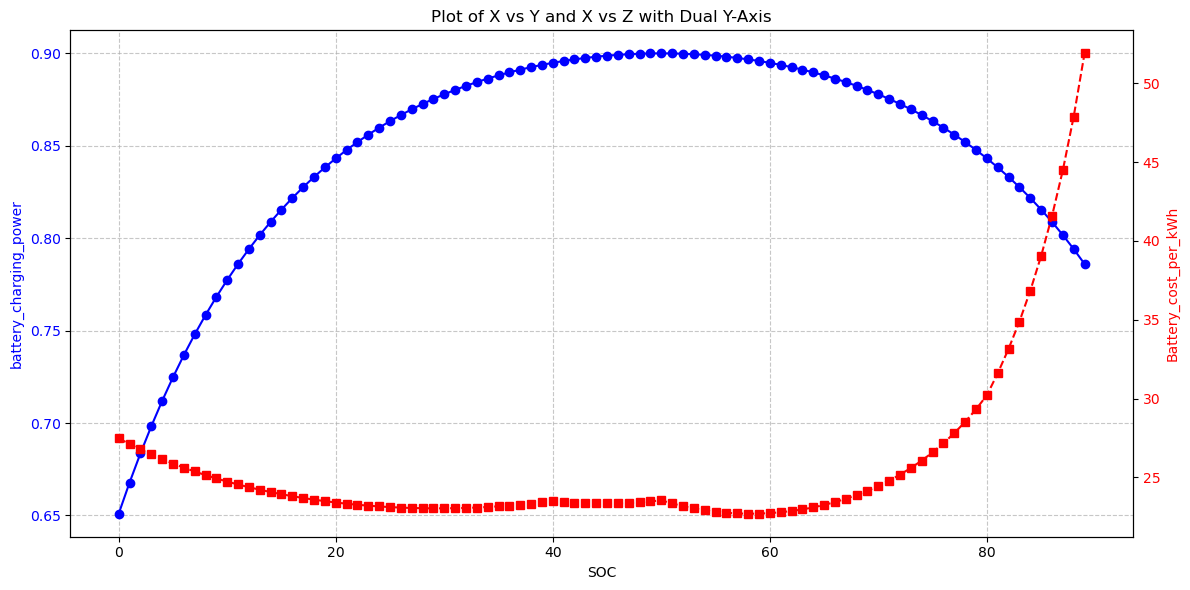

In [253]:
min_soc = 0
mx_soc = 90
battery_capacity_degradation = 0.1
x = [soc for soc in range(min_soc,mx_soc)]
# y = [give_cycles_from_dod(100-soc) for soc in range(min_soc,mx_soc)]
# y = [battery_charging_power(100-soc,battery_capacity) for soc in range(min_soc,mx_soc)]
y = [1-0.1*math.exp(0.05*(soc-50)*(soc-50)/100) for soc in range(min_soc,mx_soc)]
z = [battery_cost_per_kWh(soc,basic_price_per_kWh,battery_capacity,battery_capacity_degradation, cycle_derating,
                         max_soc,charging_efficiency,discharging_efficiency,
                         maintenance_cost_per_cycle,solar_cost) for soc in range(min_soc,mx_soc)]

# Create a plot
fig, ax1 = plt.subplots(figsize=(12, 6))  # Create a figure and axis for y vs x

# Plot y vs x on the primary y-axis
ax1.plot(x, y, marker='o', linestyle='-', color='b', label='Y vs X')
ax1.set_xlabel("SOC")
ax1.set_ylabel("battery_charging_power", color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True, linestyle='--', alpha=0.7)

# Create a secondary y-axis for z
ax2 = ax1.twinx()
ax2.plot(x, z, marker='s', linestyle='--', color='r', label='Z vs X')
ax2.set_ylabel("Battery_cost_per_kWh", color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title("Plot of X vs Y and X vs Z with Dual Y-Axis")
fig.tight_layout()  # Adjust layout to prevent overlap
plt.show()
# battery lower bound (235V) -> SOC kya h, vary with load
# battery life (soh)

10 0.9
11 0.9
12 0.9
13 0.9
14 0.9
15 0.9
16 0.9
17 0.9
18 0.9
19 0.9
20 0.9
21 0.9
22 0.9
23 0.9
24 0.9
25 0.9
26 0.9
27 0.9
28 0.9
29 0.9
30 0.9
31 0.9
32 0.9
33 0.9
34 0.9
35 0.9
36 0.9
37 0.9
38 0.9
39 0.9
40 0.9
41 0.9
42 0.9
43 0.9
44 0.9
45 0.9
46 0.9
47 0.9
48 0.9
49 0.9
50 0.9
51 0.9
52 0.9
53 0.9
54 0.9
55 0.9
56 0.9
57 0.9
58 0.9
59 0.9
60 0.9
61 0.9
62 0.9
63 0.9
64 0.9
65 0.9
66 0.9
67 0.9
68 0.9
69 0.9
70 0.9
71 0.9
72 0.9
73 0.9
74 0.9
75 0.9
76 0.9
77 0.9
78 0.9
79 0.9
80 0.9
81 0.9
82 0.9
83 0.9
84 0.9
85 0.9
86 0.9
87 0.9
88 0.9
89 0.9


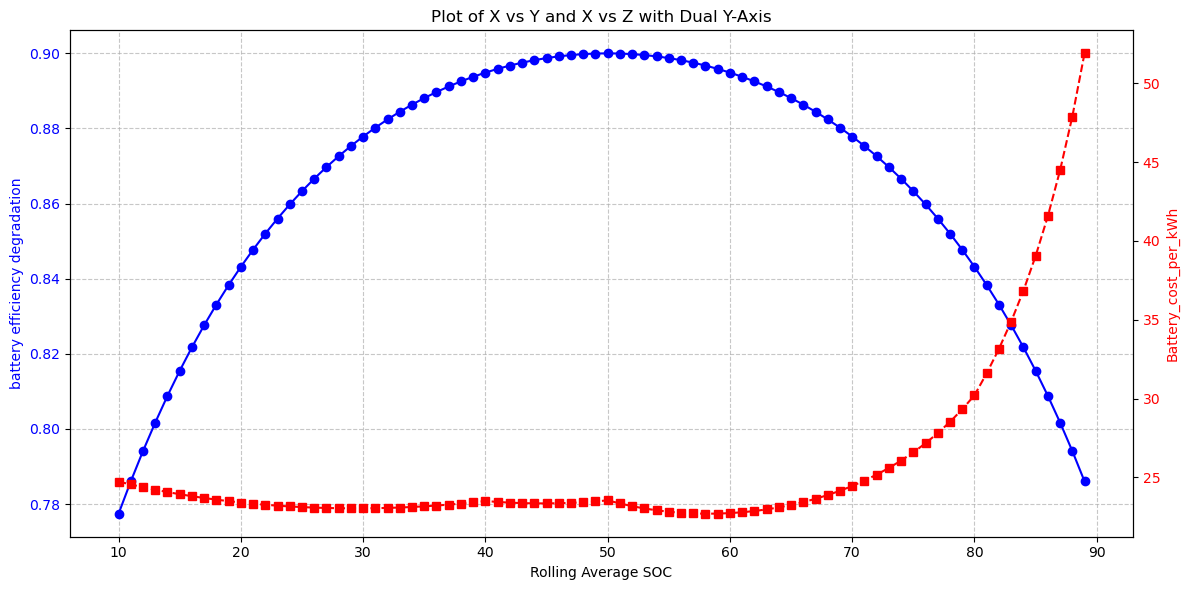

In [249]:
min_soc = 10
mx_soc = 90
x = [soc for soc in range(min_soc,mx_soc)]
# y = [give_cycles_from_dod(100-soc) for soc in range(min_soc,mx_soc)]
# y = [battery_charging_power(100-soc,battery_capacity) for soc in range(min_soc,mx_soc)]
y = [1-0.1*math.exp(0.05*(soc-50)*(soc-50)/100) for soc in range(min_soc,mx_soc)]
z = [battery_cost_per_kWh(soc,basic_price_per_kWh,battery_capacity,battery_capacity_degradation,cycle_derating,
                         max_soc,charging_efficiency,discharging_efficiency,
                         maintenance_cost_per_cycle,solar_cost) for soc in range(min_soc,mx_soc)]

# Create a plot
fig, ax1 = plt.subplots(figsize=(12, 6))  # Create a figure and axis for y vs x

# Plot y vs x on the primary y-axis
ax1.plot(x, y, marker='o', linestyle='-', color='b', label='Y vs X')
ax1.set_xlabel("Rolling Average SOC")
ax1.set_ylabel("battery efficiency degradation", color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True, linestyle='--', alpha=0.7)

# Create a secondary y-axis for z
ax2 = ax1.twinx()
ax2.plot(x, z, marker='s', linestyle='--', color='r', label='Z vs X')
ax2.set_ylabel("Battery_cost_per_kWh", color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title("Plot of X vs Y and X vs Z with Dual Y-Axis")
fig.tight_layout()  # Adjust layout to prevent overlap
plt.show()
# battery lower bound (235V) -> SOC kya h, vary with load
# battery life (soh)

In [243]:
z[80-10]

52.39836827543242

In [241]:
z[70-10]

36.19208533143129

In [233]:
z[60-10]

31.278366243649188

In [231]:
z[50-10]

31.631270213003233

In [235]:
z[40-10]

32.28380532099479

In [237]:
z[30-10]

34.21287861991658

In [239]:
z[20-10]

41.42429785604851

## Average Battery Capacity

In [129]:
f(4,avg_soc_values)

array([0.75759893, 0.76283041, 0.76810031, 0.77340894, 0.77875658,
       0.78414355, 0.78957015, 0.79503667, 0.80054345, 0.80609078,
       0.81167898, 0.81730837, 0.82297926, 0.82869199, 0.83444687,
       0.84024423, 0.84608441, 0.85196773, 0.85789454, 0.86386516,
       0.86987994, 0.87593923, 0.88204337, 0.88819272, 0.89438761,
       0.90062841, 0.90691548, 0.91324918, 0.91962987, 0.92605791,
       0.93253369, 0.92605791, 0.91962987, 0.91324918, 0.90691548,
       0.90062841, 0.89438761, 0.88819272, 0.88204337, 0.87593923,
       0.86987994, 0.86386516, 0.85789454, 0.85196773, 0.84608441,
       0.84024423, 0.83444687, 0.82869199, 0.82297926, 0.81730837,
       0.81167898, 0.80609078, 0.80054345, 0.79503667, 0.78957015,
       0.78414355, 0.77875658, 0.77340894, 0.76810031, 0.76283041,
       0.75759893, 0.75240558, 0.74725006, 0.74213209, 0.73705137,
       0.73200763, 0.72700057, 0.72202993, 0.71709541, 0.71219674,
       0.70733364, 0.70250586, 0.6977131 , 0.69295512, 0.68823

In [51]:
battery_cost_per_kWh(50,basic_price_per_kWh,battery_capacity,0,cycle_derating,
                         max_soc,charging_efficiency,discharging_efficiency,
                         maintenance_cost_per_cycle,solar_cost)

50 2000 6.0


18.925379477838497

0 [35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58
 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82
 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97] [1543.75 1565.   1586.25 1607.5  1628.75 1650.   1685.   1720.   1755.
 1790.   1825.   1860.   1895.   1930.   1965.   2000.   2065.7  2132.4
 2199.1  2265.8  2332.5  2399.2  2465.9  2532.6  2599.3  2666.   2732.7
 2799.4  2866.1  2932.8  2999.5  3066.2  3132.9  3199.6  3266.3  3333.
 3399.7  3466.4  3533.1  3599.8  3666.5  3733.2  3799.9  3866.6  3933.3
 4000.   4000.   4000.   4000.   4000.   4000.   4000.   4000.   4000.
 4000.   4000.   4000.   4000.   4000.   4000.   4000.   4000.   4000.  ] [ 5.  5.  5.  5.  5.  5.  5.  5.  5.  5.  5.  6.  6.  6.  6.  6.  6.  6.
  7.  7.  7.  7.  7.  7.  8.  8.  8.  8.  8.  9.  9.  9.  9.  9.  9. 10.
 10. 10. 10. 10. 11. 11. 11. 11. 11. 11. 11. 11. 11. 11. 11. 11. 11. 11.
 11. 11. 11. 11. 11. 11. 11. 11. 11.] [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.

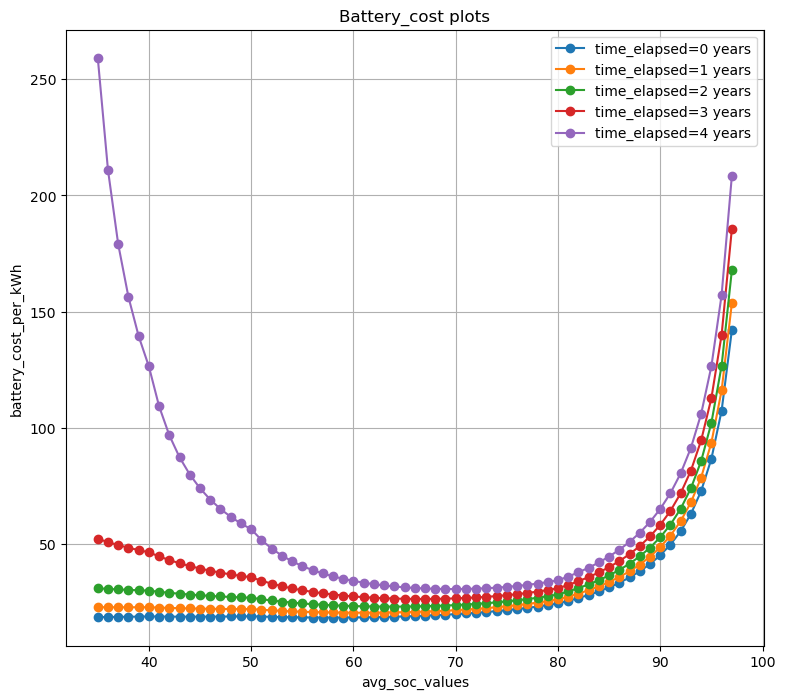

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Given values
t_values = np.array([0,1,2,3,4]) #,11,12,13,14,15,16,17,18,19,20])  # x-axis (time values)
avg_soc_values = np.array([i for i in range(35,98)])  # Different k values

plt.figure(figsize=(9, 8))

for t in t_values:
    y_values = battery_cost_per_kWh(avg_soc_values,basic_price_per_kWh,battery_capacity,t,cycle_derating,
                         max_soc,charging_efficiency,discharging_efficiency,
                         maintenance_cost_per_cycle,solar_cost)
    plt.plot(avg_soc_values, y_values, marker='o', label=f'time_elapsed={t} years')

plt.xlabel('avg_soc_values')
plt.ylabel('battery_cost_per_kWh')
plt.title('Battery_cost plots')
plt.legend()
plt.grid(True)

plt.show()

In [269]:
k_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
threshold = 0.05  # 5% (0.05 in decimal)

# Compute t for each k
t_values = {k: np.log(threshold) / -k for k in k_values}

# Print results
for k, t in t_values.items():
    print(f"For k = {k}, t = {t:.2f}")

For k = 0.1, t = 29.96
For k = 0.2, t = 14.98
For k = 0.3, t = 9.99
For k = 0.4, t = 7.49
For k = 0.5, t = 5.99
For k = 0.6, t = 4.99
